In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import math
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

In [2]:
!python smaparsing_individualstocks.py


python: can't open file '/home/pedrosalgado22/Documents/Github Repositories/SMAstrategy/smaparsing.py': [Errno 2] No such file or directory


In [ ]:
original_data_path = Path.home() / "Documents" / "Github Repositories" / "SMAstrategy" / "data" / "raw"

processed_data_path = Path.home() / "Documents" / "Github Repositories" / "SMAstrategy" / "data" / "processed"

In [ ]:
results_data_path = Path.home() / "Documents" / "Github Repositories" / "SMAstrategy" / "data" / "results"
results_data_path.mkdir(parents=True, exist_ok=True)

In [5]:
# sorry for excessive quotations, trying to quit lazy Ai code writing habits

In [6]:
# Indexes are only comparable between themselves, and not between each other for most cases - different starts, circumstances

In [7]:
PAYMENT = 500 # per month ( unrealistic, obviously. figurative value not accounting for inflation)
INTEREST_RATE = 0.03 # 3% interest rate for cash in the bank
START_DATE = "1986-01-01"

DIV_YIELD = {   # approximate long-run annual yields; decimals, not percentages
    # hindsight winners
    "microsoft": 0.008, "apple": 0.005, "amazon": 0.0, "nvidia": 0.0005,
    "alphabet": 0.0003, "meta": 0.0005, "broadcom": 0.009,
    "tesla": 0.0, "netflix": 0.0, "visa": 0.0065, "mastercard": 0.0045,
    # long-time US giants
    "exxon": 0.037, "ibm": 0.026, "ge": 0.025, "coca_cola": 0.024,
    "jnj": 0.024, "pg": 0.027, "walmart": 0.011, "jpmorgan": 0.025,
    "berkshire": 0.0, "eli_lilly": 0.024, "costco": 0.006, "oracle": 0.005,
    # fell hard but still trade
    "citigroup": 0.025, "aig": 0.012, "intel": 0.018, "cisco": 0.009,
    "boeing": 0.022, "nokia": 0.040,
    # based outside the US
    "nestle": 0.027, "bp": 0.065, "siemens": 0.035, "toyota": 0.018,
    "tsmc": 0.020, "tencent": 0.004, "samsung": 0.011, "alibaba": 0.0015,
    "asml": 0.007, "aramco": 0.048,
}                                                                       


                    # dictionaries
STRATEGIES = {"DCA": None}          
for i in range(2, 201):
    STRATEGIES[f"SMA{i}"] = f"sma_{i}"

In [8]:
def simulate(df, sma_timeframe, dividend_yield, values=None): # function can receive a values argument, but it doesn't have to
    dates = df.index.tolist()
    closes = df["Close"].tolist()
    if sma_timeframe is not None:
        smas = df[sma_timeframe].tolist() # every days calculated sma in a list

    valid = df[(df.index >= START_DATE) & df["sma_200"].notna()]  # first day with sma_200 available. filtered dataframe with only "valid" rows
    start = df.index.get_loc(valid.index[0]) # first column where in valid. this will iterate for all datasets not one df with all indexes one per df
    end = df.index.get_loc(valid.index[-1])


    cash = 0
    units = 0
    units_bought = 0
    total_invested_stocks = 0
    last_sma_value_when_buying = 0
    total_invested = 0
    last_value_bought = 0
    n_buys = 0
    next_payment = dates[start].replace(day=1) + pd.DateOffset(months=1)       # next_payment = dates[start] + pd.Timedelta(days=(7 - dates[start].weekday()) % 7) for weekly simulations



    for i in range(start, end + 1):
        days = (dates[i] - dates[i - 1]).days # days between i row and i-1 row as int (.days returns int). used for interest/dividend calculations (since there are not rows for all days)
        cash = cash * (1 + INTEREST_RATE) ** (days / 365)
        units = units * (1 + dividend_yield) ** (days / 365)

        while next_payment <= dates[i]: # checks if payday has come
            cash += PAYMENT
            total_invested += PAYMENT # total invested is both cash and stock
            next_payment += pd.DateOffset(months=1) # next_payment += pd.Timedelta(days=7) for weekly simulations

        if sma_timeframe is None:
            signal = True       # if no sma_timeframe is provided, the signal is always True (DCA strategy)
        else:
            signal = closes[i - 1] < smas[i - 1] # if the previous day's close is below the previous day's sma_x, then the signal is True (buy signal)

        if cash > 0 and signal == True: # if there is cash available and the signal is True, then buy
            units = units + cash / closes[i-1]
            units_bought += cash / closes[i-1]
            total_invested_stocks += cash
            n_buys += 1
            cash = 0
            last_value_bought = closes[i-1]
            if sma_timeframe is not None:
                last_sma_value_when_buying = smas[i - 1]

        if values is not None:
            values.append(units * closes[i] + cash)   # so that we can plot the value of the portfolio over time later is not doing much here

    final_value = units * closes[-1] + cash
    keys = {
        "strategy_simulated": sma_timeframe if sma_timeframe is not None else "DCA",
        "start_date": dates[start].date(),
        "end_date": dates[-1].date(),
        "total_invested": total_invested,
        "total_invested_stocks": total_invested_stocks,
        "final_value": final_value,
        "total_return_pct": (final_value / total_invested - 1) * 100,
        "units": units,
        "avg_price": total_invested_stocks / units_bought if units_bought > 0 else None,
        "leftover_cash": cash,
        "n_buys": n_buys,
        "last_close": closes[i],
        "last_value_bought": last_value_bought,
        "last_sma_value_when_buying": last_sma_value_when_buying
    }

    return pd.DataFrame([keys], index=[keys["strategy_simulated"]]) # returns df with all those columns and index is the strategy

In [9]:
def run_index_simulator(df, name):
    results = [] # always need to maintain empty list to receive att
    for strategy, sma_timeframe in STRATEGIES.items():
        results.append(simulate(df, sma_timeframe, DIV_YIELD[name]))

        
    table = pd.concat(results)
    table.insert(0, "index", name)   # first column holds the index name
    return table

In [10]:
df = pd.read_csv(processed_data_path / "apple_indprocessed.csv", index_col=0, parse_dates=True)


In [11]:
run_index_simulator(df,"apple")

,index,strategy_simulated,start_date,end_date,total_invested,total_invested_stocks,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys,last_close,last_value_bought,last_sma_value_when_buying
DCA,apple,DCA,1986-01-02,2026-10-16,244500,244500.000000,1.892190e+08,77290.200516,551040.478997,0.519660,0.000000,489,343.38501,333.019989,0.000000
sma_2,apple,sma_2,1986-01-02,2026-10-16,244500,244533.210493,1.878386e+08,76725.596815,547020.338309,0.523574,0.000000,489,343.38501,330.320007,331.669998
sma_3,apple,sma_3,1986-01-02,2026-10-16,244500,244543.299124,1.881824e+08,76866.218162,548021.602730,0.522631,0.000000,489,343.38501,333.019989,333.606659
sma_4,apple,sma_4,1986-01-02,2026-10-16,244500,244555.657471,1.882614e+08,76898.522929,548251.621960,0.522442,0.000000,488,343.38501,333.019989,335.472496
sma_5,apple,sma_5,1986-01-02,2026-10-16,244500,244568.341400,1.881795e+08,76865.024282,548013.101963,0.522716,0.000000,488,343.38501,333.019989,335.562000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sma_196,apple,sma_196,1986-01-02,2026-10-16,244500,244036.211766,1.714980e+08,70042.330667,499423.280878,0.571435,3530.299193,213,343.38501,246.190659,248.538138
sma_197,apple,sma_197,1986-01-02,2026-10-16,244500,244036.702717,1.714984e+08,70042.479928,499424.343658,0.571435,3530.299193,213,343.38501,246.190659,248.264843
sma_198,apple,sma_198,1986-01-02,2026-10-16,244500,244040.466445,1.714654e+08,70028.995408,499328.330000,0.571555,3530.299193,213,343.38501,246.190659,248.008281
sma_199,apple,sma_199,1986-01-02,2026-10-16,244500,244060.109191,1.714691e+08,70030.498421,499339.031882,0.571587,3530.299193,212,343.38501,246.190659,247.744446


In [13]:

pd.set_option("display.float_format", "{:,.2f}".format)   # no scientific notation, 2 decimals, thousands commas


all_tables = []
for name in DIV_YIELD:
    df = pd.read_csv(processed_data_path / f"{name}_indprocessed.csv", index_col=0, parse_dates=True)
    all_tables.append(run_index_simulator(df, name))

all_tables = pd.concat(all_tables)


display(all_tables)
all_tables.to_parquet(results_data_path / "results_full200.csv", index=False)

,index,strategy_simulated,start_date,end_date,total_invested,total_invested_stocks,final_value,total_return_pct,units,avg_price,leftover_cash,n_buys,last_close,last_value_bought,last_sma_value_when_buying
DCA,microsoft,DCA,1986-12-24,2026-10-16,239000,"239,000.00","85,056,750.15","35,488.60","161,789.44",1.98,0.00,478,525.72,512.90,0.00
sma_2,microsoft,sma_2,1986-12-24,2026-10-16,239000,"239,024.42","85,028,640.87","35,476.84","161,735.97",1.98,0.00,478,525.72,512.80,512.85
sma_3,microsoft,sma_3,1986-12-24,2026-10-16,239000,"239,035.52","85,111,131.54","35,511.35","161,892.88",1.98,0.00,478,525.72,522.61,527.22
sma_4,microsoft,sma_4,1986-12-24,2026-10-16,239000,"239,047.39","84,815,397.75","35,387.61","161,330.36",1.98,0.00,478,525.72,522.61,526.71
sma_5,microsoft,sma_5,1986-12-24,2026-10-16,239000,"239,056.51","84,818,998.01","35,389.12","161,337.20",1.98,0.00,478,525.72,522.61,524.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
sma_196,aramco,sma_196,2020-09-30,2026-10-15,36500,"36,714.70","43,071.98",18.01,"1,703.80",24.74,0.00,36,25.28,25.22,25.64
sma_197,aramco,sma_197,2020-09-30,2026-10-15,36500,"36,718.95","43,066.36",17.99,"1,703.57",24.74,0.00,36,25.28,25.22,25.62
sma_198,aramco,sma_198,2020-09-30,2026-10-15,36500,"36,718.95","43,066.36",17.99,"1,703.57",24.74,0.00,36,25.28,25.22,25.61
sma_199,aramco,sma_199,2020-09-30,2026-10-15,36500,"36,721.70","43,071.61",18.00,"1,703.78",24.74,0.00,36,25.28,25.22,25.60


In [15]:


N_BINS = 10   # number of bars in the mean charts
TOP_N = 15    # how many SMAs in the top chart

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple",
          "tab:brown", "tab:pink", "tab:gray", "tab:olive", "tab:cyan"]

finals = {}  # finals[name] = final value of every strategy, same order as STRATEGIES (position 0 is DCA)

for name in DIV_YIELD:
    df = pd.read_csv(processed_data_path / f"{name}_indprocessed.csv", index_col=0, parse_dates=True)
    df = df.dropna(subset=["Close"])
    finals[name] = []
    for strategy, sma_col in STRATEGIES.items():
        result = simulate(df, sma_col, DIV_YIELD[name])
        finals[name].append(result["final_value"].iloc[0])

names = list(DIV_YIELD)
strategy_names = list(STRATEGIES)   # DCA, SMA2, SMA3 ...
n_rows = (len(names) + 2) // 3      # 3 charts per row, grows with more indexes

x_values = []  # the sma length of each strategy
for strategy in STRATEGIES:
    if strategy == "DCA":
        x_values.append(1)             # sma 1 is the same as DCA
    else:
        x_values.append(int(strategy[3:]))   # "SMA50" -> 50

bin_size = math.ceil(len(strategy_names) / N_BINS)  # 200 strategies and 10 bins gives 20 per bin

bin_labels = []  # 1-20, 21-40, ...
for first in range(0, len(x_values), bin_size):
    last = min(first + bin_size, len(x_values)) - 1
    bin_labels.append(f"{x_values[first]}-{x_values[last]}")


def get_bin_means(values):  # mean final amount of each bin
    means = []
    for first in range(0, len(values), bin_size):
        group = values[first:first + bin_size]
        means.append(sum(group) / len(group))
    return means


def make_grid():  # one square per index, hides the empty squares at the end
    fig, axes = plt.subplots(n_rows, 3, figsize=(18, 4 * n_rows))
    axes = axes.flatten()
    for j in range(len(names), len(axes)):
        axes[j].axis("off")
    return axes

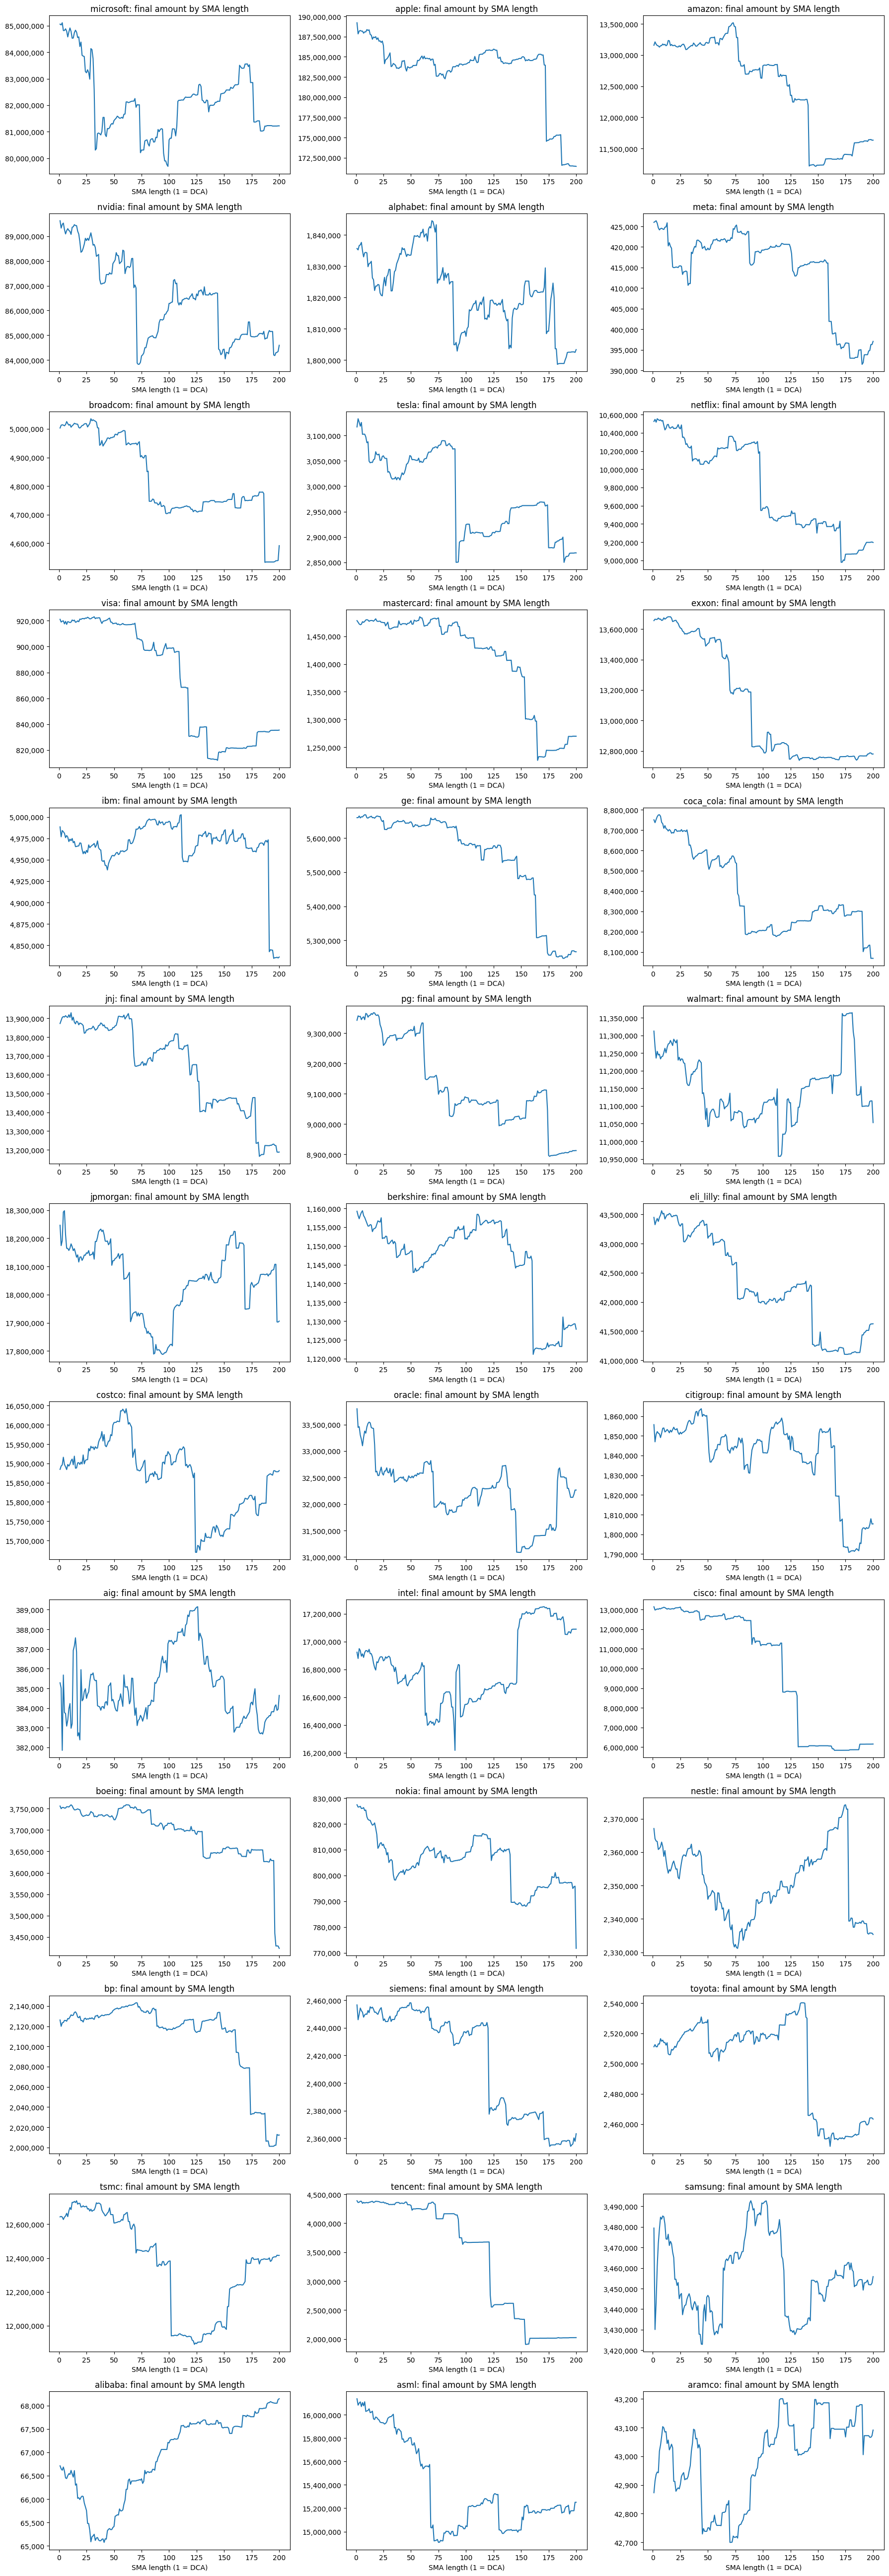

In [16]:
axes = make_grid()
for i in range(len(names)):
    ax = axes[i]
    ax.plot(x_values, finals[names[i]])
    ax.set_title(f"{names[i]}: final amount by SMA length")
    ax.set_xlabel("SMA length (1 = DCA)")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()

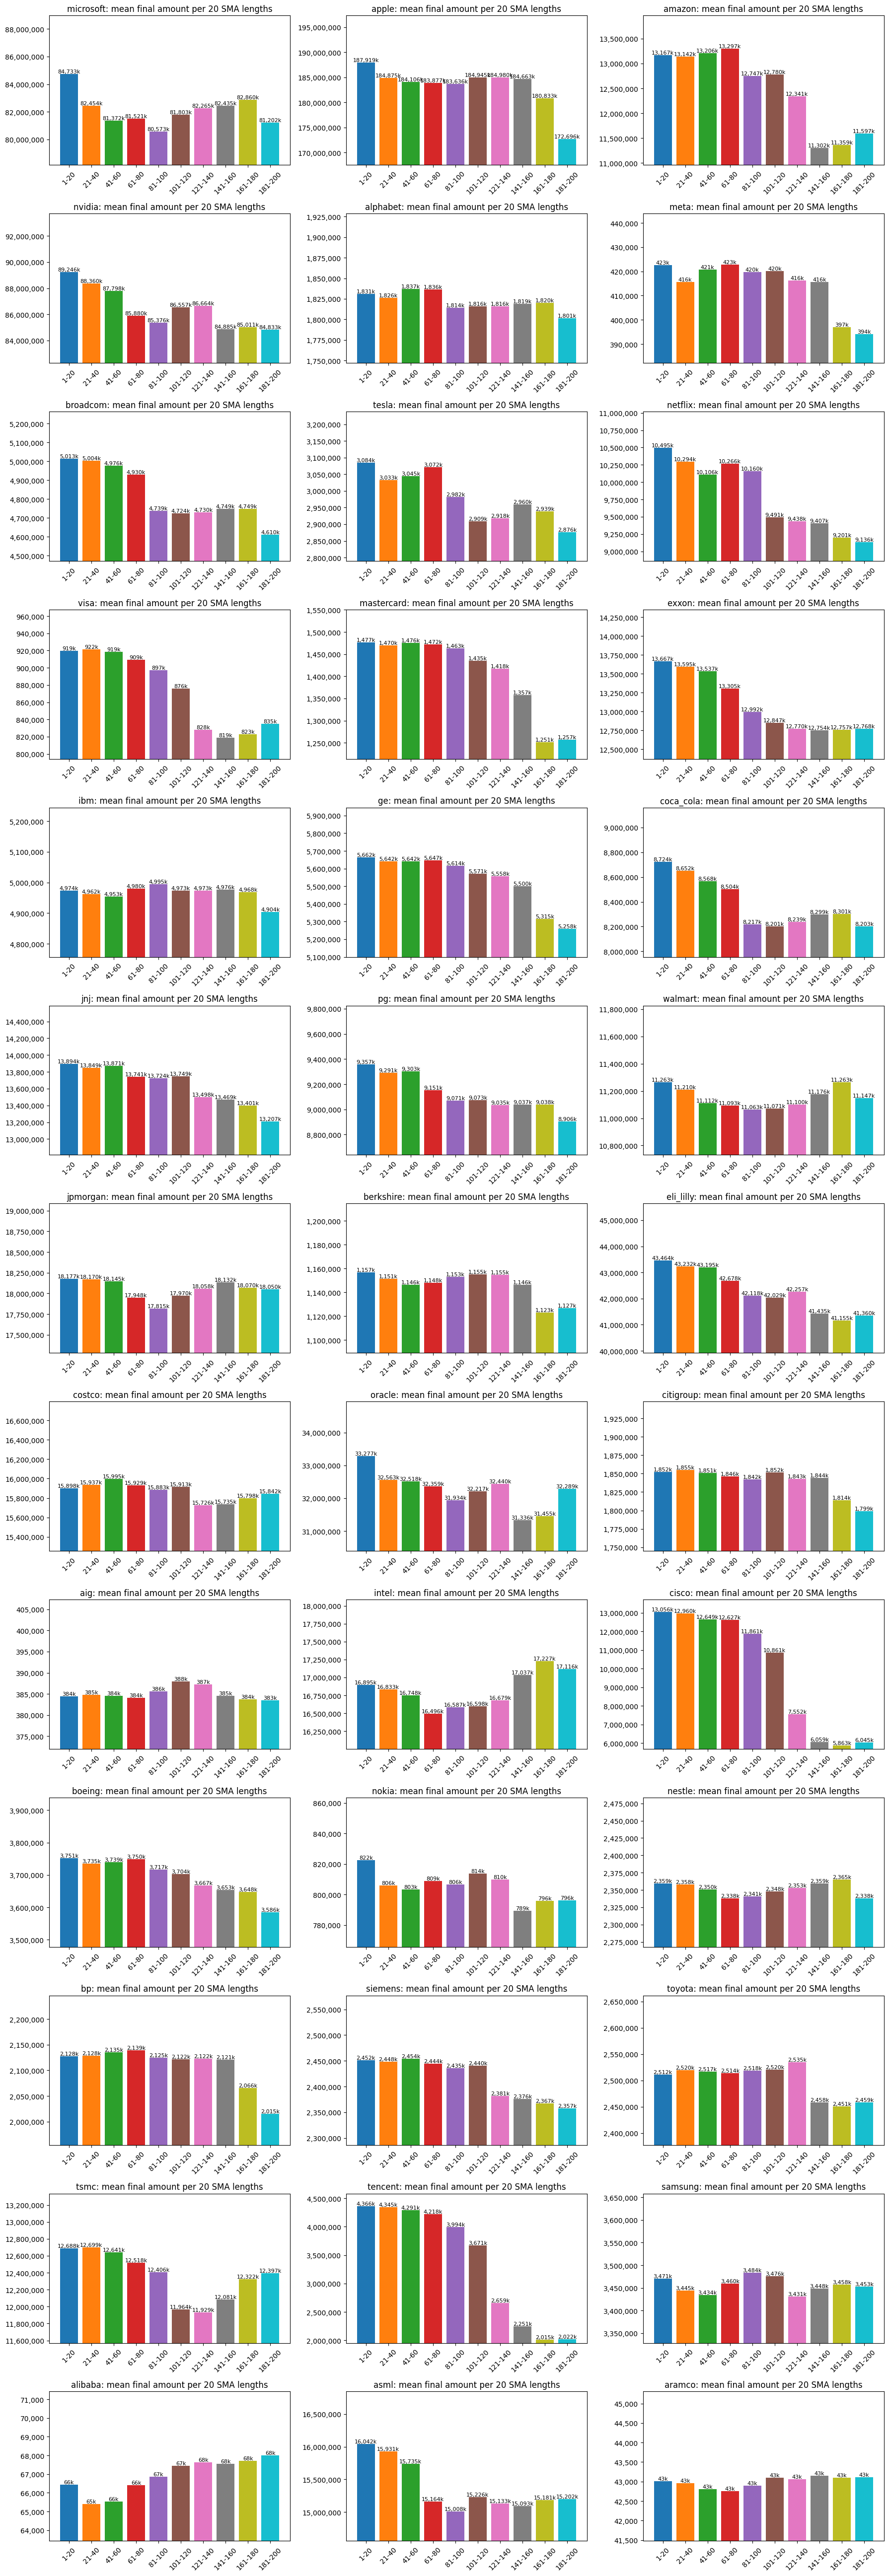

In [17]:
axes = make_grid()
for i in range(len(names)):
    ax = axes[i]
    means = get_bin_means(finals[names[i]])
    labels = []
    for mean in means:
        labels.append(f"{mean / 1000:,.0f}k")
    bars = ax.bar(bin_labels, means, color=colors)
    ax.bar_label(bars, labels=labels, fontsize=8)
    ax.set_ylim(bottom=min(means) * 0.97)
    ax.set_title(f"{names[i]}: mean final amount per {bin_size} SMA lengths")
    ax.tick_params(axis="x", labelrotation=45)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()

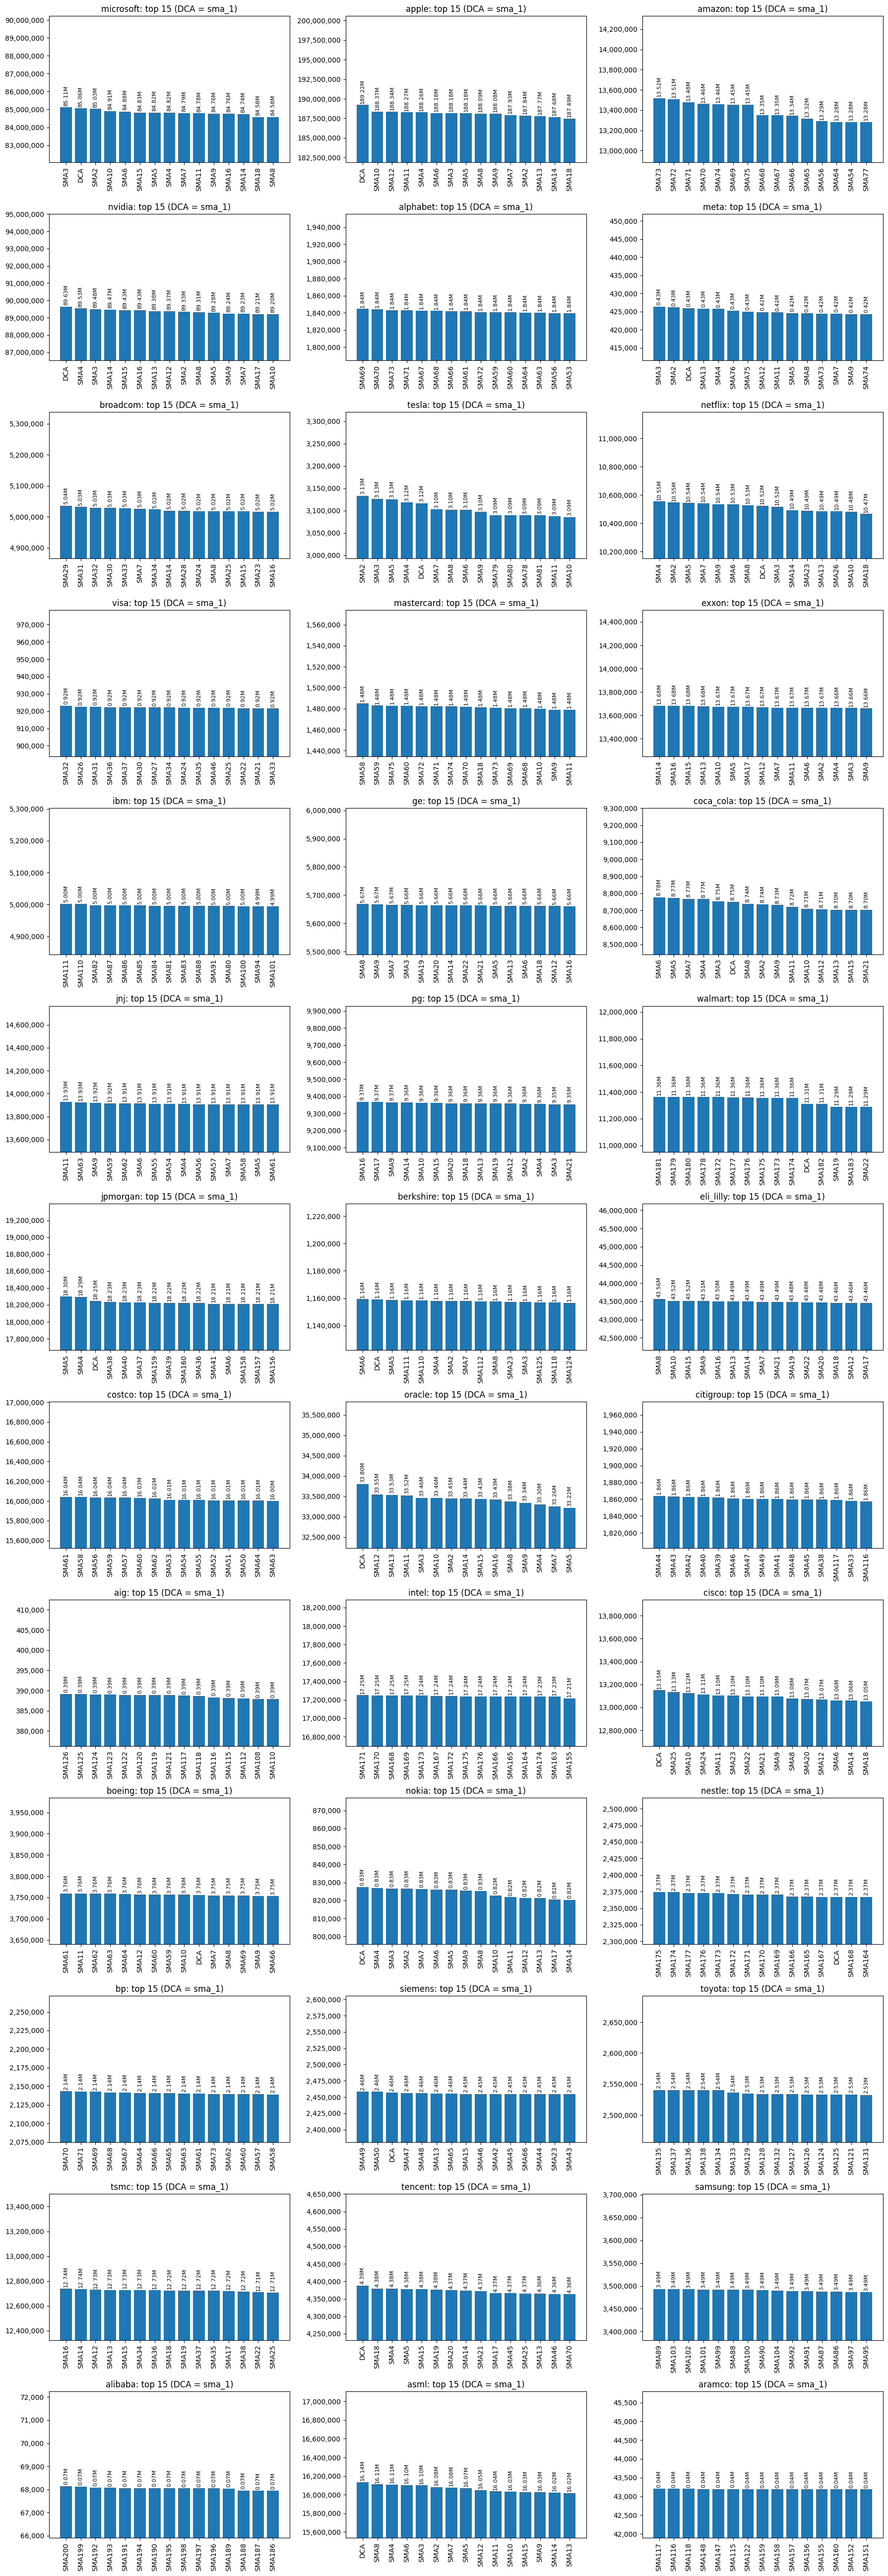

In [18]:
axes = make_grid()
for i in range(len(names)):
    ax = axes[i]
    ranking = []
    for k in range(len(strategy_names)):
        ranking.append((finals[names[i]][k], strategy_names[k]))
    ranking.sort(reverse=True)  # biggest final amount first

    top_names = []
    top_values = []
    labels = []
    for rank in range(min(TOP_N, len(ranking))):
        value, strategy = ranking[rank]
        top_names.append(strategy)
        top_values.append(value)
        labels.append(f"{value / 1000000:.2f}M")

    bars = ax.bar(top_names, top_values, color="tab:blue")
    ax.bar_label(bars, labels=labels, rotation=90, fontsize=8, padding=2)
    ax.set_ylim(min(top_values) * 0.97, max(top_values) * 1.06)
    ax.set_title(f"{names[i]}: top {TOP_N} (DCA = sma_1)")
    ax.tick_params(axis="x", labelrotation=90)
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()

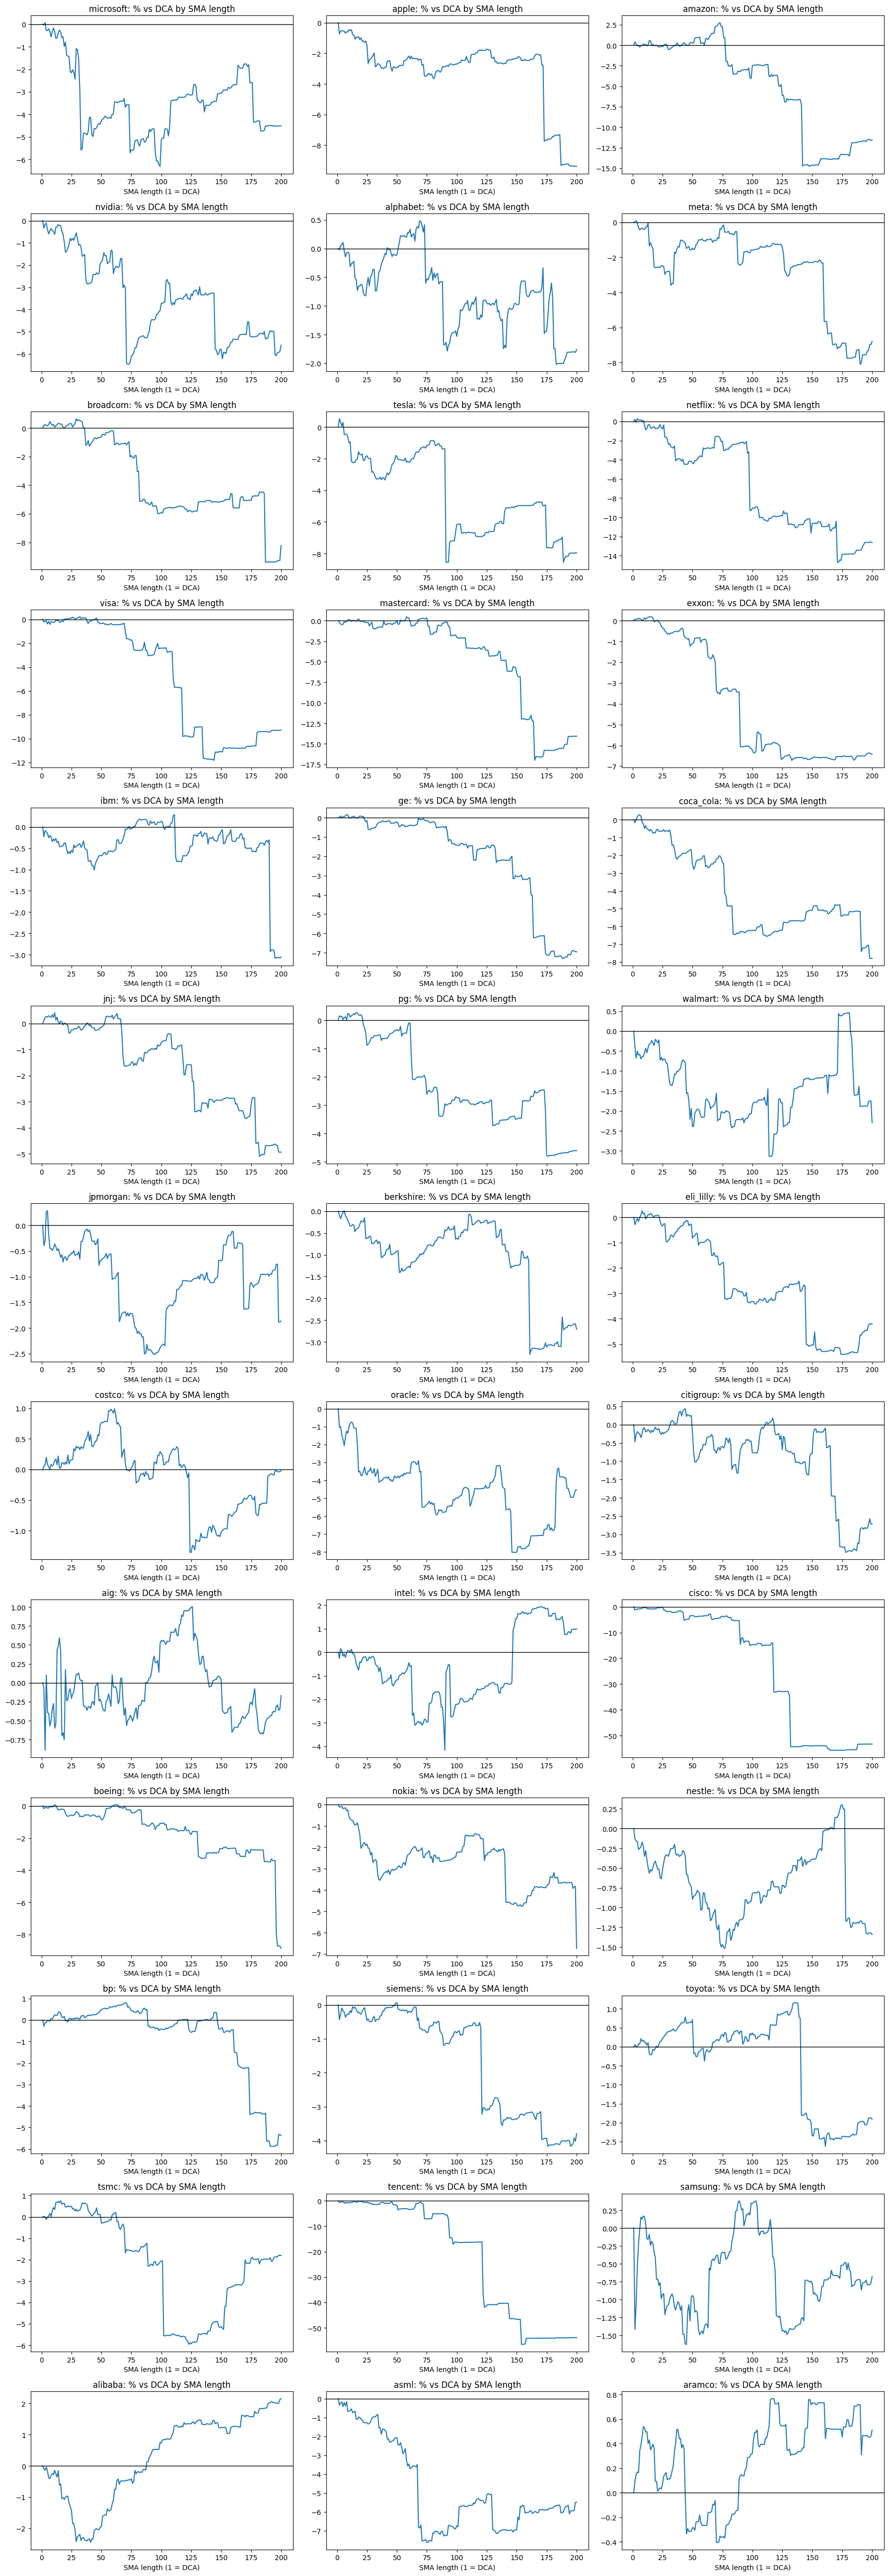

In [19]:
axes = make_grid()
for i in range(len(names)):
    ax = axes[i]
    dca = finals[names[i]][0]
    diffs = []
    for value in finals[names[i]]:
        diffs.append((value / dca - 1) * 100)
    ax.plot(x_values, diffs)
    ax.axhline(0, color="black", linewidth=1)  # above this line = beats DCA
    ax.set_title(f"{names[i]}: % vs DCA by SMA length")
    ax.set_xlabel("SMA length (1 = DCA)")
plt.tight_layout()
plt.show()

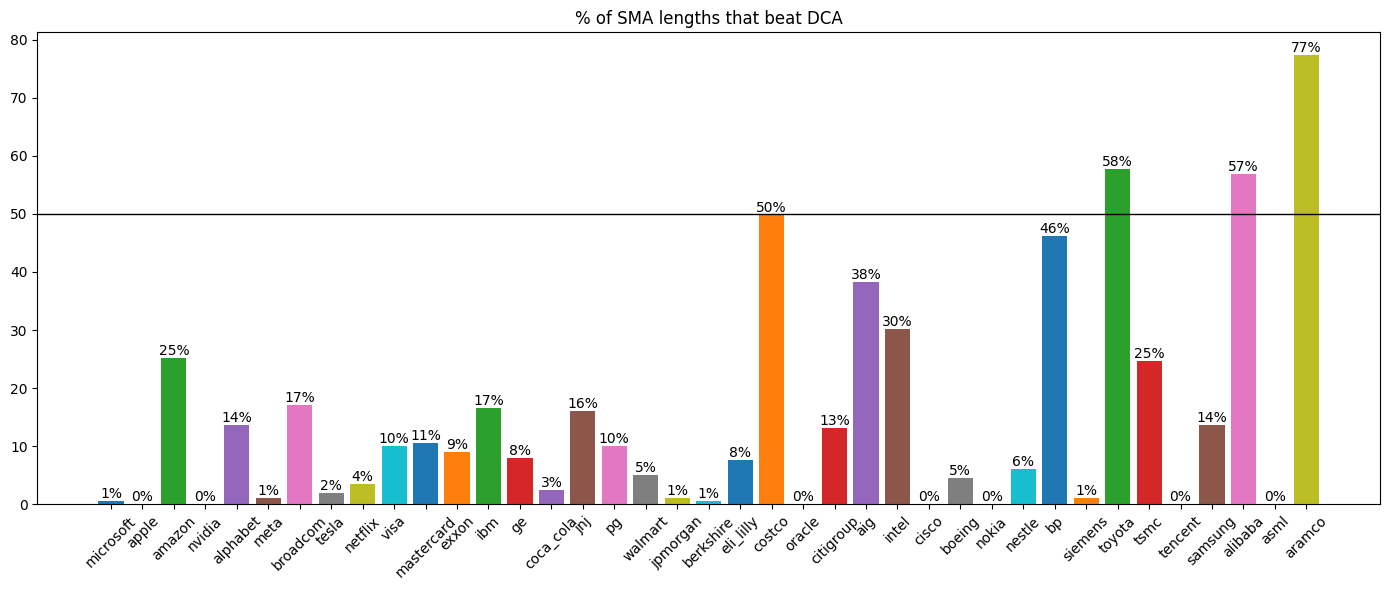

In [20]:
beat_pct = []
labels = []
for name in names:
    dca = finals[name][0]
    beat = 0
    for value in finals[name][1:]:  # skip DCA itself
        if value > dca:
            beat += 1
    pct_beat = beat / (len(finals[name]) - 1) * 100
    beat_pct.append(pct_beat)
    labels.append(f"{pct_beat:.0f}%")

fig, ax = plt.subplots(figsize=(14, 6))
bars = ax.bar(names, beat_pct, color=colors)
ax.bar_label(bars, labels=labels)
ax.axhline(50, color="black", linewidth=1)
ax.set_title("% of SMA lengths that beat DCA")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()

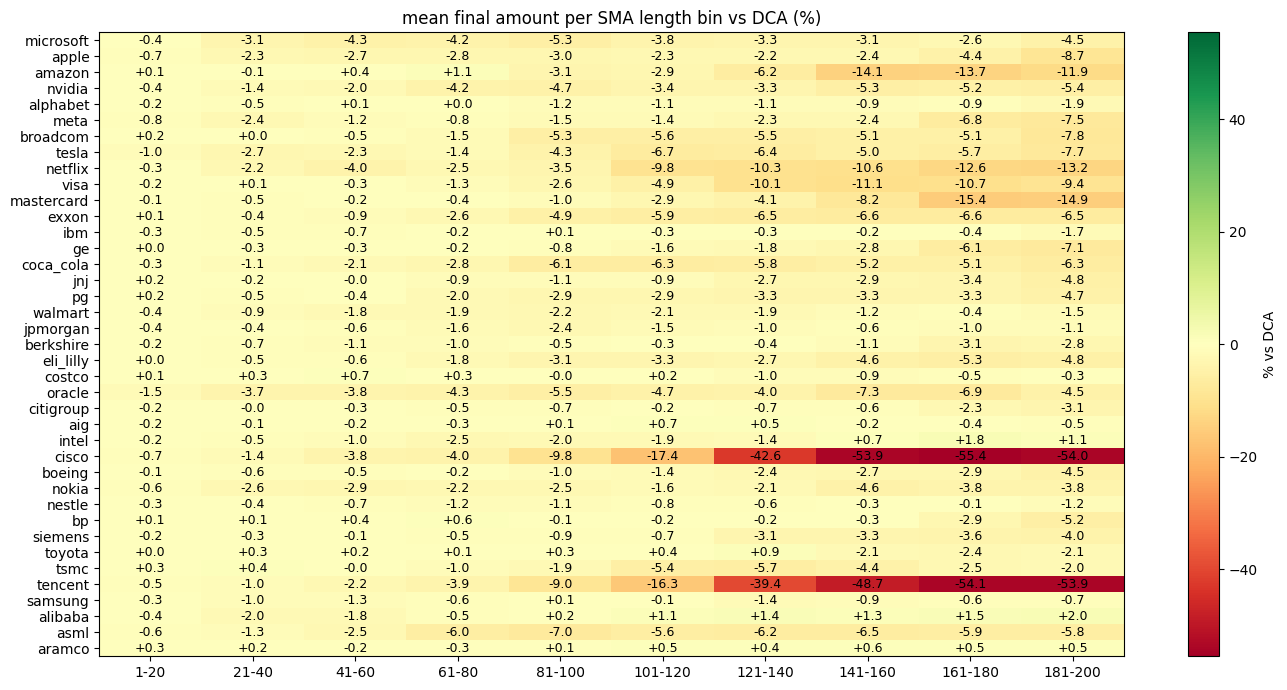

In [21]:
grid = []
for name in names:
    means = get_bin_means(finals[name])
    row = []
    for mean in means:
        row.append((mean / finals[name][0] - 1) * 100)
    grid.append(row)

biggest = 0  # symmetric color scale so 0 is the middle color
for row in grid:
    for value in row:
        if abs(value) > biggest:
            biggest = abs(value)

fig, ax = plt.subplots(figsize=(14, 7))
image = ax.imshow(grid, cmap="RdYlGn", vmin=-biggest, vmax=biggest, aspect="auto")  # green = beats DCA, red = loses
ax.set_xticks(range(len(bin_labels)))
ax.set_xticklabels(bin_labels)
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names)
for r in range(len(names)):
    for c in range(len(bin_labels)):
        ax.text(c, r, f"{grid[r][c]:+.1f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, label="% vs DCA")
ax.set_title("mean final amount per SMA length bin vs DCA (%)")
plt.tight_layout()
plt.show()

In [37]:
# ---- settings ----
BLOCK = 3                           # points hidden on each side of the test point during cross-validation
HALF_LIST = [4, 5, 8, 12, 20, 30]   # windows to try; each must be bigger than BLOCK

# ---- check the inputs ----
for name in names:
    assert len(finals[name]) == len(x_values), name   # one final amount per strategy


def average_around(values, k, half, hide):
    # Average of the points within `half` positions of point k (window shrinks at the edges).
    # Points within `hide` positions of k are skipped. hide = -1 skips nothing, so k itself counts.
    total = 0
    count = 0
    for j in range(max(0, k - half), min(len(values), k + half + 1)):
        if abs(j - k) > hide:
            total += values[j]
            count += 1
    return total / count


def cv_miss(values, half):
    # Cross-validation score of one window size (lower is better).
    # Each point is predicted from its neighbours with itself and its BLOCK closest neighbours hidden.
    # The closest neighbours are hidden because SMA 10 and 11 give nearly the same result,
    # so leaving them in would let the test cheat.
    total = 0
    for k in range(len(values)):
        miss = average_around(values, k, half, BLOCK) - values[k]
        total += miss ** 2
    return total / len(values)


rows = []
for name in names:
    values = finals[name]   # final amount of each SMA length for this stock

    # 1. the plain best SMA, no smoothing
    raw_best = x_values[values.index(max(values))]

    # 2. cross-validation picks the window size with the smallest miss
    misses = []
    for half in HALF_LIST:
        misses.append(cv_miss(values, half))
    best_half = HALF_LIST[misses.index(min(misses))]

    # 3. replace every point with the average of its window, the highest averaged point is the answer
    averaged = []
    for k in range(len(values)):
        averaged.append(average_around(values, k, best_half, -1))
    averaged_best = x_values[averaged.index(max(averaged))]

    rows.append([name, raw_best, best_half, averaged_best])

display(pd.DataFrame(rows, columns=["stock", "raw best sma", "best HALF", "averaged best sma"]))

,stock,raw best sma,best HALF,averaged best sma
0,microsoft,3,4,1
1,apple,1,4,1
2,amazon,73,4,71
3,nvidia,1,4,1
4,alphabet,69,4,69
5,meta,3,4,1
6,broadcom,29,4,30
7,tesla,2,4,1
8,netflix,4,4,3
9,visa,32,5,31
